# Collections Medallion Pipeline
**PySpark data engineering · synthetic collections operations**

## tl;dr
The locally executed Spark pipeline reconciles 300,275 deliveries to 300,000 canonical events, quarantines three invalid rows, and publishes $25.30M in generated payments. All 12 independent reconciliations and eight tests pass. These results demonstrate engineering mechanics, not real portfolio performance.

## Context & Methods
The pipeline uses explicit schemas and Parquet Bronze/Silver/Gold layers. The second Silver version unions the first with the new batch and deduplicates by stable event ID. Saved outputs below come from Spark 4.0.1.

### Key assumptions
All data are synthetic. Contact outcomes and payments are independently generated. Channel differences are not causal. [Definitions and architecture](docs/ARCHITECTURE.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'outputs/portfolio_summary.json').read_text())
validation=json.loads((root/'outputs/validation.json').read_text())
print('Canonical events:',f"{summary['events']:,}")
print('Payments:',f"${summary['payments_cents']/100:,.2f}")
print('Independent checks:',validation['passed_checks'])

Canonical events: 300,000
Payments: $25,298,590.35
Independent checks: 12


## Data
### Incremental ingestion evidence
The second delivery contains redeliveries and three deliberately invalid records. Canonical grain remains one row per event ID.

In [2]:
batches=pd.read_json(root/'outputs/batch_metrics.json')
display(batches)

batch,raw_rows,accepted_rows_before_cross_batch_dedup,quarantined_rows,silver_rows_after_merge,distinct_event_ids_after_merge
batch_01,204000,204000,0,204000,204000
batch_02,96275,96272,3,300000,300000


## Results
### Monthly generated payments

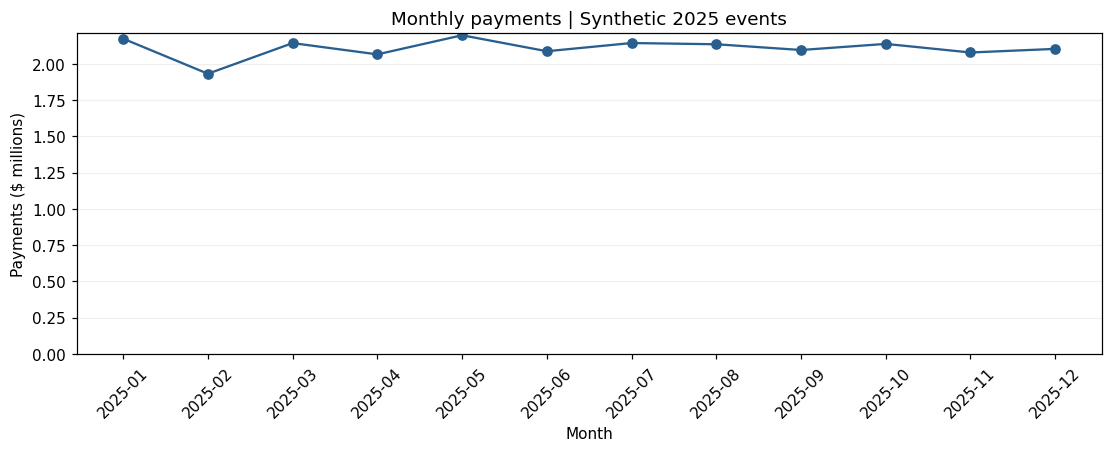

In [3]:
monthly=pd.read_csv(root/'outputs/monthly_kpis.csv')
trend=monthly.groupby('event_month',as_index=False).payments_cents.sum()
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
ax.plot(trend.event_month,trend.payments_cents/1e8,marker='o',color='#285f8f')
ax.set(title='Monthly payments | Synthetic 2025 events',xlabel='Month',ylabel='Payments ($ millions)')
ax.tick_params(axis='x',rotation=45);ax.grid(axis='y',alpha=.2);ax.set_ylim(bottom=0)
display(fig);plt.close(fig)

### Channel contact metrics
Promise-to-pay counts as a right-party contact. Differences reflect random variation around the same generator distribution.

channel,attempts,right_party_contacts,promises_to_pay,rpc_rate,ptp_per_attempt
letter,54216,17841,7477,0.3291,0.1379
sms,54333,17885,7645,0.3292,0.1407
phone,53912,17764,7524,0.3295,0.1396
email,54166,17958,7479,0.3315,0.1381


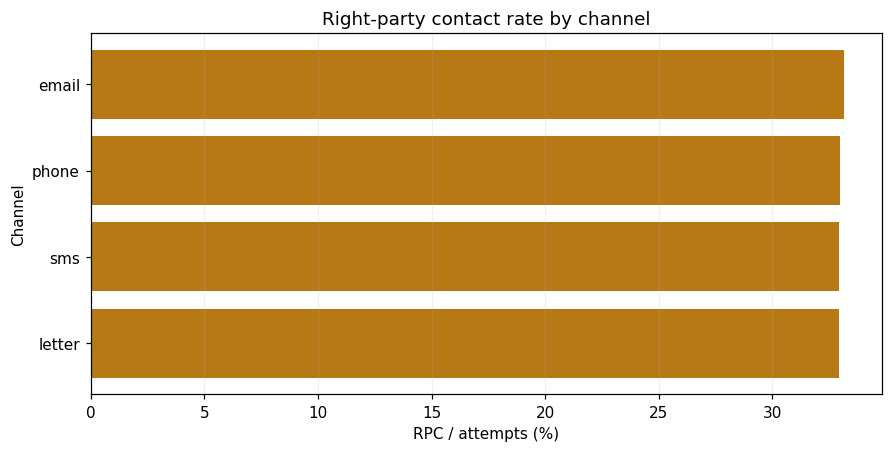

In [4]:
channel=pd.read_csv(root/'outputs/channel_performance.csv').sort_values('rpc_rate')
display(channel.round(4))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
ax.barh(channel.channel,channel.rpc_rate*100,color='#b87816')
ax.set(title='Right-party contact rate by channel',xlabel='RPC / attempts (%)',ylabel='Channel');ax.set_xlim(left=0);ax.grid(axis='x',alpha=.2)
display(fig);plt.close(fig)

## Takeaways
The pipeline proves schema enforcement, quarantine routing, duplicate-safe incremental versioning, partitioned Parquet output, Gold KPI construction, and independent reconciliation. It does not prove outreach effectiveness or production scalability. A production design needs transactional lakehouse storage, orchestration, concurrency controls, governance, monitoring, and late-event rules.

[Full findings](FINDINGS.md) · [Validation](outputs/validation.json)